# Premier League Match Outcome Model — Predicting Fixtures

Loads the model trained in `01_epl_training_evaluation.ipynb` and scores any fixture.
Needs `epl_model.joblib` and `epl_features.py` (both produced by notebook 1) in the same folder.

> Probabilities come from team form and Elo only — no lineups, injuries, odds or xG. Use them as a statistical baseline, not a betting edge.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from epl_features import build_features

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

state = joblib.load("epl_model.joblib")
hist = state["long_history"]
latest_season = int(hist.season.max())
active_teams = sorted(hist[hist.season == latest_season].team.unique())
print(f"Model: {state['best_name']} | history through {hist.date.max().date()} | season {latest_season}")
print(f"{len(active_teams)} teams in the current season:", ", ".join(active_teams))

Model: LogReg compact (Elo+shots) | history through 2026-09-20 | season 2027
20 teams in the current season: Arsenal, Aston Villa, Bournemouth, Brentford, Brighton, Chelsea, Coventry, Crystal Palace, Everton, Fulham, Hull, Ipswich, Leeds, Liverpool, Man City, Man United, Newcastle, Nott'm Forest, Sunderland, Tottenham


## Current team strength (Elo)

,Man City,Arsenal,Liverpool,Brighton,Man United,Brentford,Bournemouth,Aston Villa,Leeds,Newcastle,Everton,Chelsea,Hull,Nott'm Forest,Sunderland,Fulham,Coventry,Crystal Palace,Tottenham,Ipswich
elo,1690,1680,1588,1580,1575,1555,1543,1533,1527,1525,1521,1520,1519,1509,1492,1485,1471,1470,1429,1410


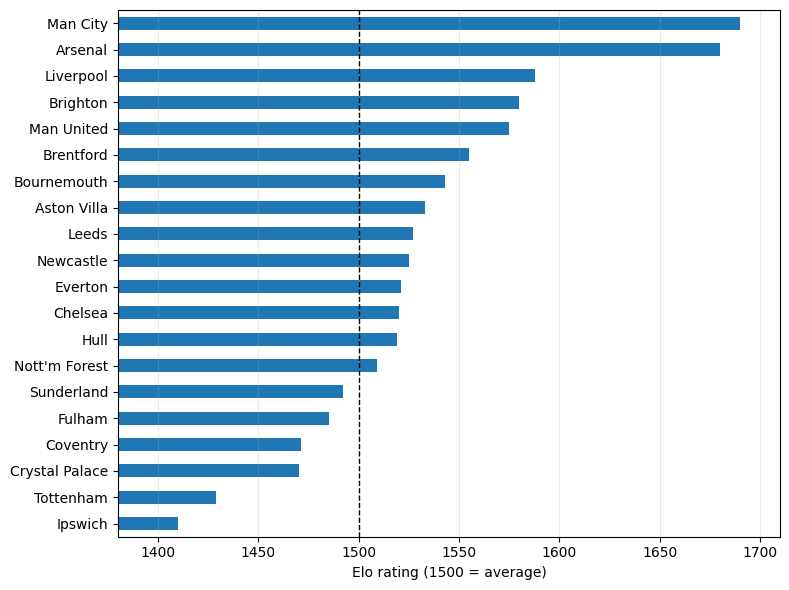

In [2]:
elo = (pd.Series(state["elo_ratings"], name="elo").loc[active_teams]
         .sort_values(ascending=False).round(0).astype(int))
display(elo.to_frame().T)

fig, ax = plt.subplots(figsize=(8, 6))
elo.sort_values().plot.barh(ax=ax, color="#1f77b4")
ax.axvline(1500, color="k", ls="--", lw=1)
ax.set_xlim(elo.min() - 30, elo.max() + 20); ax.set_xlabel("Elo rating (1500 = average)")
ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()

## Predict a fixture

`predict_fixture` appends the match to the history and builds features strictly from games **before** the given date.
If no date is passed it assumes one week after the last match in the data.

In [3]:
from epl_features import fixture_features

def predict_fixtures(fixtures):
    """fixtures: list of (home, away) or (home, away, 'YYYY-MM-DD'). Returns a DataFrame of probabilities."""
    m = fixture_features(hist, fixtures, state["elo_ratings"], latest_season)
    p = state["model"].predict_proba(m[state["features"]])          # columns follow state["classes"] = [A, D, H]
    out = m[["date", "home", "away"]].copy()
    out["date"] = out["date"].dt.date
    out["p_home"], out["p_draw"], out["p_away"] = p[:, 2], p[:, 1], p[:, 0]
    out["pick"] = np.where(p.argmax(1) == 2, m.home, np.where(p.argmax(1) == 1, "Draw", m.away))
    out["elo_home"], out["elo_away"] = m.elo_h.round().astype(int), m.elo_a.round().astype(int)
    return out.reset_index(drop=True)

def show(df):
    return (df.style.format({"p_home": "{:.1%}", "p_draw": "{:.1%}", "p_away": "{:.1%}"})
              .background_gradient(subset=["p_home", "p_draw", "p_away"], cmap="Blues", axis=None))

display(predict_fixtures([("Arsenal", "Chelsea", "2026-10-17")]))

,date,home,away,p_home,p_draw,p_away,pick,elo_home,elo_away
0,2026-10-17,Arsenal,Chelsea,0.704813,0.188749,0.106438,Arsenal,1680,1520


## Predict several fixtures at once

Edit the list below with real upcoming fixtures (team names must match the CSV spelling, e.g. `"Man City"`, `"Nott'm Forest"`).

In [5]:
fixtures = [
    ("Arsenal",    "Leeds",     "2026-10-17"),
    ("Liverpool",   "Man City",   "2026-10-11"),
    ("Chelsea",  "Bournemouth",   "2026-10-10"),
    ("Aston Villa","Brentford",     "2026-10-10"),
    ("Man United", "Tottenham",       "2026-10-10"),
    ("Ipswich", "Fulham", "2026-10-10"),
    ('Sunderland', "Brighton", "2026-10-10"),
    ("Hull", "Everton", "2026-10-11"),
    ("Crystal Palace", "Nott'm Forest", "2026-10-11"),
    ("Coventry", "Newcastle", "2026-10-13"),


]
preds = predict_fixtures(fixtures)
display(preds.round(3))

,date,home,away,p_home,p_draw,p_away,pick,elo_home,elo_away
0,2026-10-10,Chelsea,Bournemouth,0.323,0.274,0.403,Bournemouth,1520,1543
1,2026-10-10,Aston Villa,Brentford,0.423,0.256,0.321,Aston Villa,1533,1555
2,2026-10-10,Man United,Tottenham,0.598,0.230,0.172,Man United,1575,1429
3,2026-10-10,Ipswich,Fulham,0.342,0.262,0.395,Fulham,1410,1485
4,2026-10-10,Sunderland,Brighton,0.301,0.261,0.439,Brighton,1492,1580
5,2026-10-11,Liverpool,Man City,0.311,0.259,0.429,Man City,1588,1690
6,2026-10-11,Hull,Everton,0.412,0.274,0.314,Hull,1519,1521
7,2026-10-11,Crystal Palace,Nott'm Forest,0.349,0.259,0.393,Nott'm Forest,1470,1509
8,2026-10-13,Coventry,Newcastle,0.405,0.248,0.347,Coventry,1471,1525
9,2026-10-17,Arsenal,Leeds,0.704,0.183,0.113,Arsenal,1680,1527


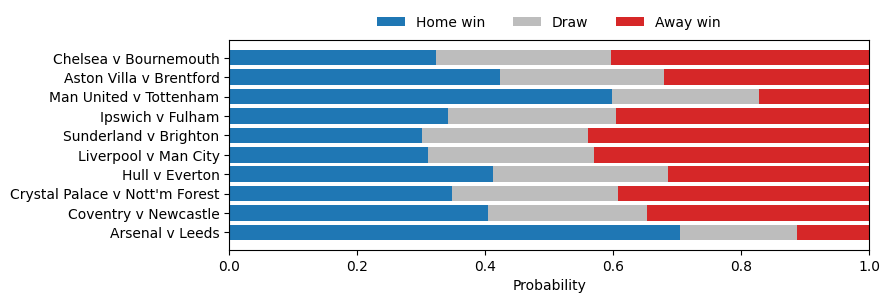

In [6]:
# Stacked-bar view of the same predictions
fig, ax = plt.subplots(figsize=(9, 3.2))
labels = [f"{h} v {a}" for h, a in zip(preds.home, preds.away)]
ax.barh(labels, preds.p_home, color="#1f77b4", label="Home win")
ax.barh(labels, preds.p_draw, left=preds.p_home, color="#bdbdbd", label="Draw")
ax.barh(labels, preds.p_away, left=preds.p_home + preds.p_draw, color="#d62728", label="Away win")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Probability")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5, 1.18))
plt.tight_layout(); plt.show()

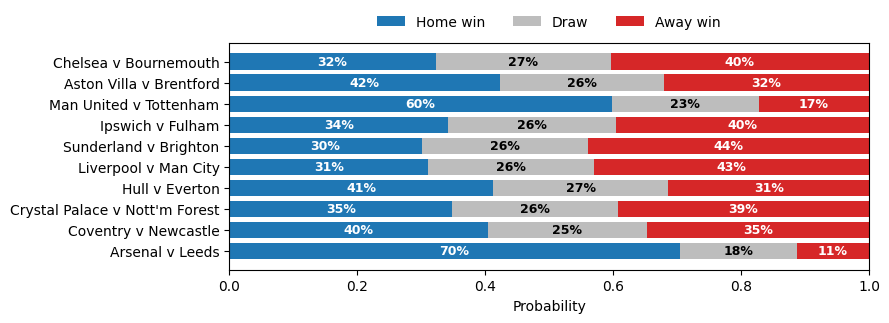

In [7]:
# Stacked-bar view of the same predictions, with percentage labels inside each segment
fig, ax = plt.subplots(figsize=(9, 3.4))
labels = [f"{h} v {a}" for h, a in zip(preds.home, preds.away)]
segments = [("p_home", "Home win", "#1f77b4", "white"),
            ("p_draw", "Draw",     "#bdbdbd", "black"),
            ("p_away", "Away win", "#d62728", "white")]

left = np.zeros(len(preds))
for col, name, color, txt in segments:
    vals = preds[col].values
    bars = ax.barh(labels, vals, left=left, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" if v >= 0.05 else "" for v in vals],   # skip labels on very thin segments
                 label_type="center", color=txt, fontsize=9, fontweight="bold")
    left += vals

ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Probability")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5, 1.18))
plt.tight_layout(); plt.show()

## Full head-to-head matrix (home team in rows, away team in columns)

Probability that the **home side wins** for every pairing of current-season teams, as of one week after the last recorded match.

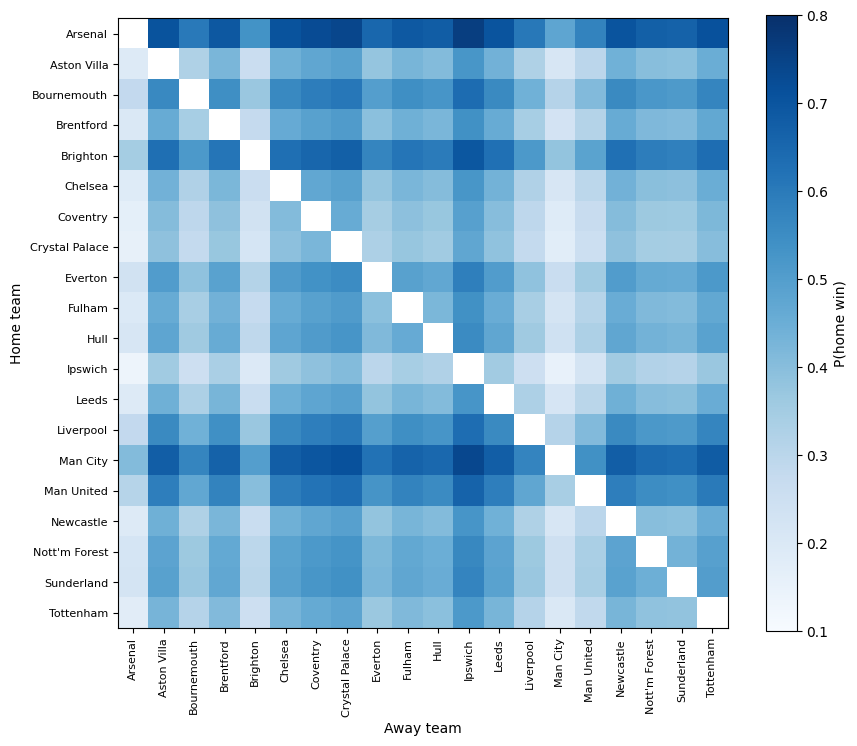

In [6]:
pairs = [(h, a) for h in active_teams for a in active_teams if h != a]
grid = predict_fixtures(pairs)
mat = grid.pivot(index="home", columns="away", values="p_home").loc[active_teams, active_teams]

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(mat.values.astype(float), cmap="Blues", vmin=0.1, vmax=0.8)
ax.set_xticks(range(len(active_teams))); ax.set_xticklabels(active_teams, rotation=90, fontsize=8)
ax.set_yticks(range(len(active_teams))); ax.set_yticklabels(active_teams, fontsize=8)
ax.set_xlabel("Away team"); ax.set_ylabel("Home team")
fig.colorbar(im, ax=ax, label="P(home win)"); plt.tight_layout(); plt.show()

In [9]:
display(predict_fixtures([("Arsenal", "Leeds", "2026-10-17")]))

,date,home,away,p_home,p_draw,p_away,pick,elo_home,elo_away
0,2026-10-17,Arsenal,Leeds,0.704024,0.183213,0.112763,Arsenal,1680,1527


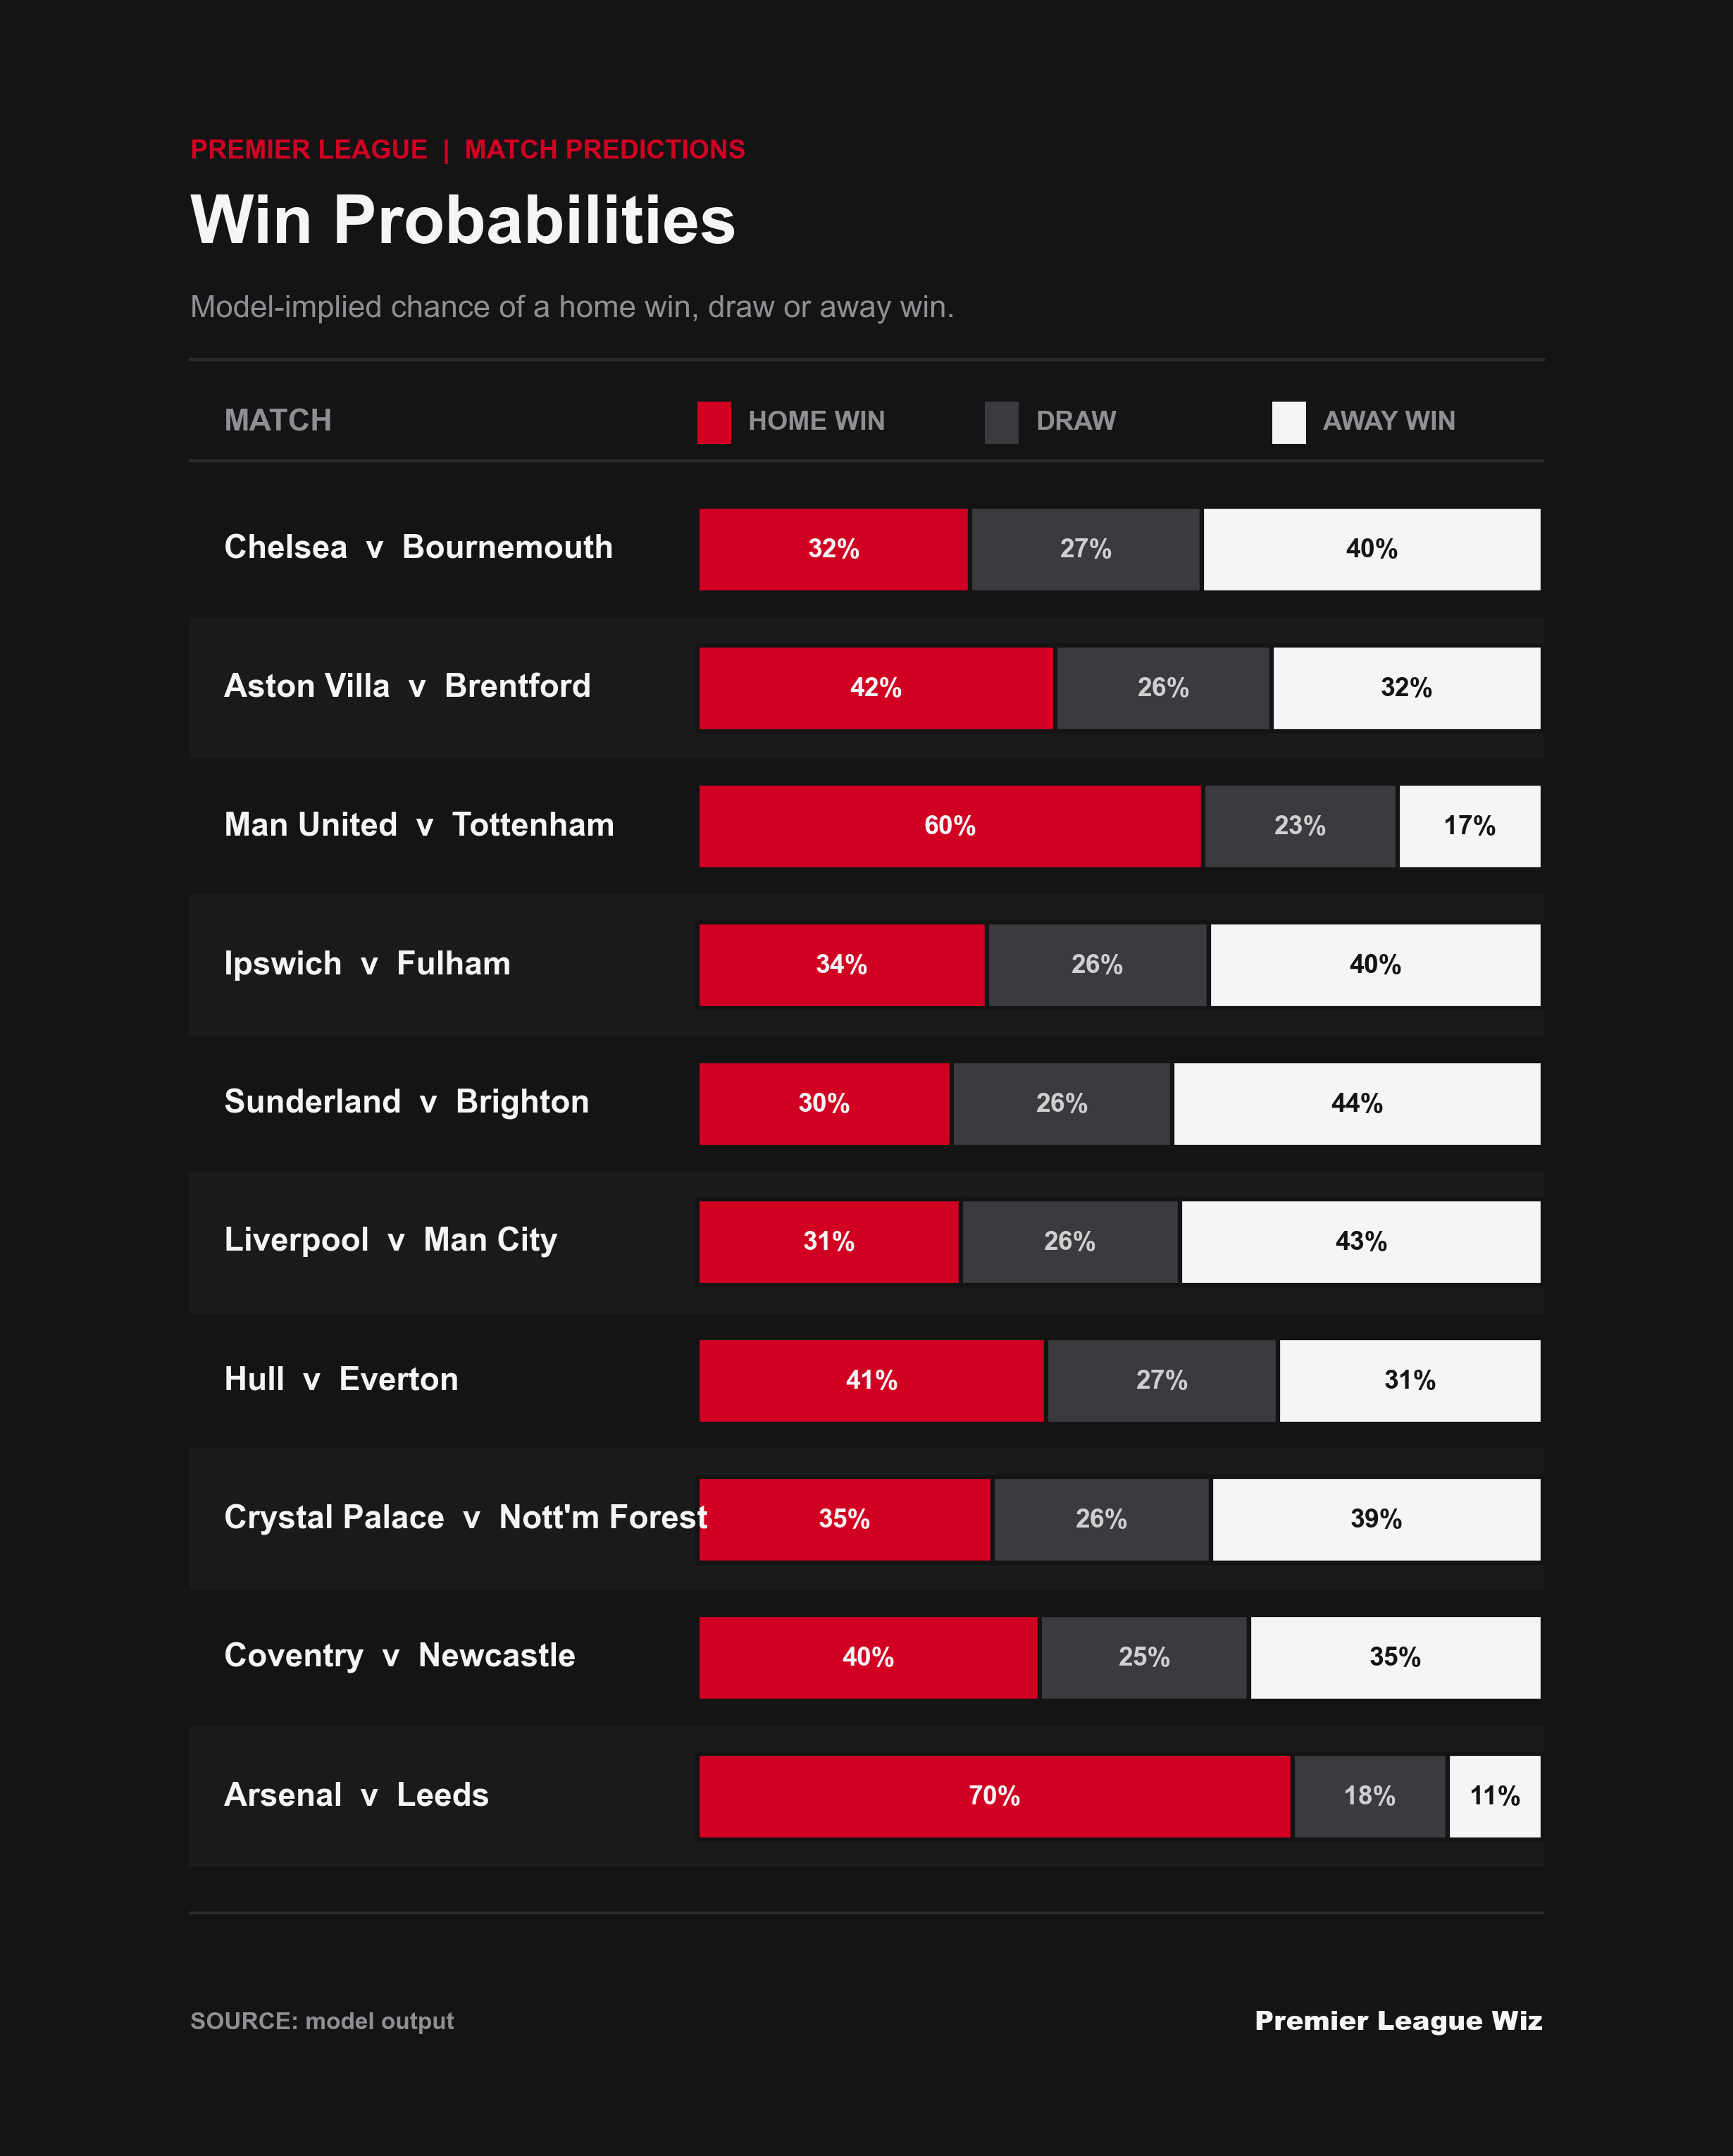

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# THEME (same tokens as the standings table)
# ------------------------------------------------------------------
THEME = {
    "bg": "#141414",          # Matte charcoal
    "border": "#2A2A2E",      # Subtle divider line
    "accent": "#D10022",      # Signature crimson
    "white": "#F5F5F5",
    "muted": "#8E8E93",
    "zebra": "#1A1A1A",       # Alternating row band
    "row_text": "#CFCFCF",
    "draw": "#3A3A3F",        # Neutral segment on charcoal
}

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Inter", "Graphik", "Helvetica Neue", "Arial", "DejaVu Sans"
]

# Segment: column, legend name, fill colour, in-bar text colour
SEGMENTS = [
    ("p_home", "HOME WIN", THEME["accent"], THEME["white"]),
    ("p_draw", "DRAW",     THEME["draw"],   THEME["row_text"]),
    ("p_away", "AWAY WIN", THEME["white"],  THEME["bg"]),
]

# Layout (0-100 coordinate space)
LABEL_X = 12            # match label, left aligned
BAR_X0, BAR_X1 = 40, 90
BAR_W = BAR_X1 - BAR_X0


def plot_predictions(
    preds,
    kicker="PREMIER LEAGUE  |  MATCH PREDICTIONS",
    title="Win Probabilities",
    subtitle="Model-implied chance of a home win, draw or away win.",
    source="SOURCE: model output",
    brand="Premier League Wiz",
    min_label=0.05,                       # skip labels on very thin segments
    outfile="the_athletic_prediction_bars.png",
):
    t = THEME
    preds = preds.reset_index(drop=True)
    n = len(preds)

    # 4:5 vertical canvas
    fig, ax = plt.subplots(figsize=(8, 10), dpi=300)
    fig.patch.set_facecolor(t["bg"])
    ax.set_facecolor(t["bg"])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")

    # Header deck
    fig.text(0.10, 0.935, kicker, fontsize=9, fontweight="bold",
             color=t["accent"], ha="left")
    fig.text(0.10, 0.895, title, fontsize=23, fontweight="heavy",
             color=t["white"], ha="left")
    fig.text(0.10, 0.860, subtitle, fontsize=10.5,
             color=t["muted"], ha="left")

    ax.plot([10, 90], [84, 84], color=t["border"], lw=1.2)

    # Legend row (replaces column headers)
    legend_y = 81.0
    ax.text(LABEL_X, legend_y, "MATCH", fontsize=10.5, color=t["muted"],
            weight="bold", ha="left", va="center")
    x = BAR_X0
    for _, name, color, _ in SEGMENTS:
        ax.add_patch(plt.Rectangle((x, legend_y - 1.0), 2.0, 2.0,
                                   color=color, lw=0))
        ax.text(x + 3.0, legend_y, name, fontsize=9, color=t["muted"],
                weight="bold", ha="left", va="center")
        x += 17

    ax.plot([10, 90], [79.2, 79.2], color=t["border"], lw=1)

    # Rows (shrink the step if there are many matches so nothing hits the footer)
    start_y = 75.0
    row_step = min(6.8, (start_y - 16) / max(n - 1, 1))
    half = row_step / 2
    bar_h = row_step * 0.62

    for idx, row in preds.iterrows():
        y = start_y - idx * row_step

        if idx % 2 == 1:
            ax.fill_between([10, 90], y - half, y + half,
                            color=t["zebra"], zorder=0)

        ax.text(LABEL_X, y, f"{row['home']}  v  {row['away']}", fontsize=11,
                color=t["white"], weight="bold", ha="left", va="center")

        left = 0.0
        for col, _, color, txt in SEGMENTS:
            v = float(row[col])
            ax.barh(y, v * BAR_W, left=BAR_X0 + left * BAR_W, height=bar_h,
                    color=color, edgecolor=t["bg"], linewidth=1.5, zorder=2)
            if v >= min_label:
                ax.text(BAR_X0 + (left + v / 2) * BAR_W, y, f"{v:.0%}",
                        fontsize=9, color=txt, weight="bold",
                        ha="center", va="center", zorder=3)
            left += v

    # Footer
    ax.plot([10, 90], [10.5, 10.5], color=t["border"], lw=1)
    fig.text(0.10, 0.05, source, fontsize=8, color=t["muted"],
             ha="left", fontweight="semibold")
    fig.text(0.90, 0.05, brand, fontsize=9, color=t["white"],
             ha="right", fontweight="black")

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(outfile, dpi=300, facecolor=t["bg"])
    plt.show()


# ------------------------------------------------------------------
# RUN (assumes `preds` has columns: home, away, p_home, p_draw, p_away)
# ------------------------------------------------------------------
plot_predictions(preds)

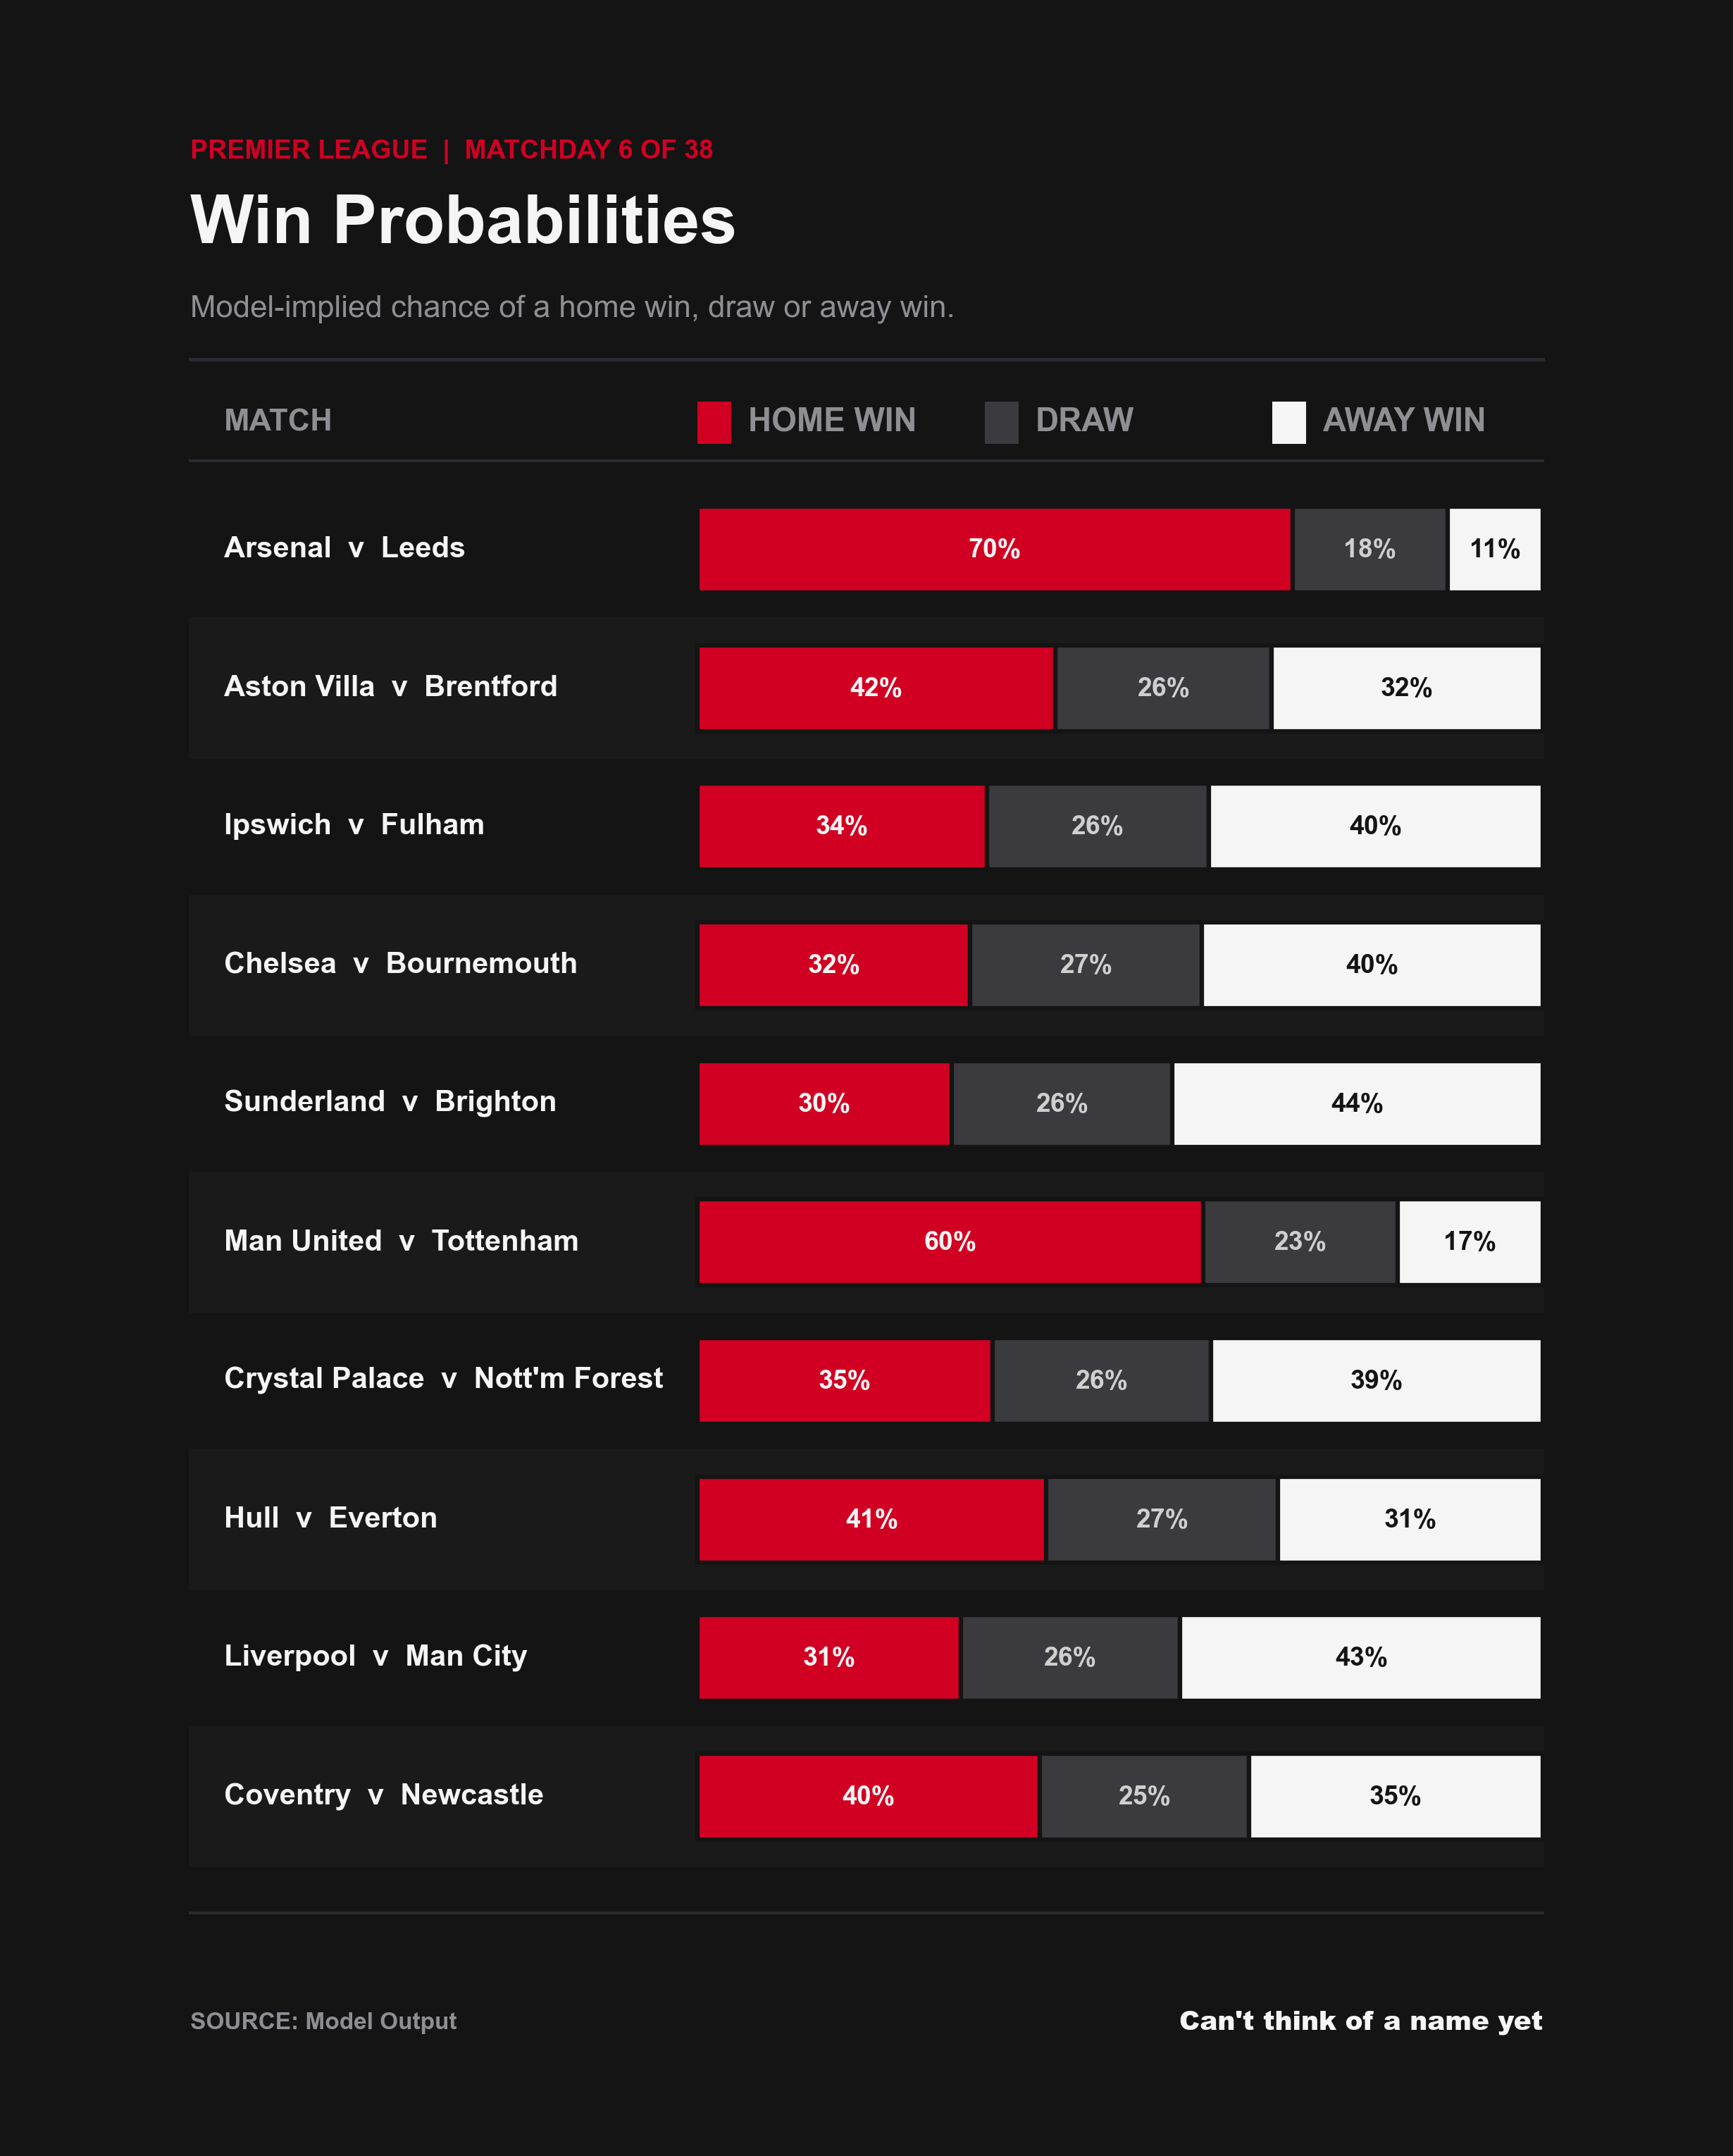

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# THEME (same tokens as the standings table)
# ------------------------------------------------------------------
THEME = {
    "bg": "#141414",          # Matte charcoal
    "border": "#2A2A2E",      # Subtle divider line
    "accent": "#D10022",      # Signature crimson
    "white": "#F5F5F5",
    "muted": "#8E8E93",
    "zebra": "#1A1A1A",       # Alternating row band
    "row_text": "#CFCFCF",
    "draw": "#3A3A3F",        # Neutral segment on charcoal
}

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Inter", "Graphik", "Helvetica Neue", "Arial", "DejaVu Sans"
]

# Segment: column, legend name, fill colour, in-bar text colour
SEGMENTS = [
    ("p_home", "HOME WIN", THEME["accent"], THEME["white"]),
    ("p_draw", "DRAW",     THEME["draw"],   THEME["row_text"]),
    ("p_away", "AWAY WIN", THEME["white"],  THEME["bg"]),
]

# Layout (0-100 coordinate space)
LABEL_X = 12            # match label, left aligned
BAR_X0, BAR_X1 = 40, 90
BAR_W = BAR_X1 - BAR_X0

# ------------------------------------------------------------------
# FIXTURE ORDER (Matchday 6 of 38, in kick-off order)
# ------------------------------------------------------------------
MATCHDAY = 6
TOTAL_MATCHDAYS = 38

FIXTURE_ORDER = [
    ("Arsenal",     "Leeds"),        # Sat 10 Oct, 5:00 pm
    ("Aston Villa", "Brentford"),    # Sat 10 Oct, 7:30 pm
    ("Ipswich Town", "Fulham"),      # Sat 10 Oct, 7:30 pm
    ("Chelsea",     "Bournemouth"),  # Sat 10 Oct, 7:30 pm
    ("Sunderland",  "Brighton"),     # Sat 10 Oct, 7:30 pm
    ("Man Utd",     "Spurs"),        # Sat 10 Oct, 10:00 pm
    ("Palace",      "Nottm Forest"), # Sun 11 Oct, 6:30 pm
    ("Hull",        "Everton"),      # Sun 11 Oct, 6:30 pm
    ("Liverpool",   "Man City"),     # Sun 11 Oct, 9:00 pm
    ("Coventry",    "Newcastle"),    # Tue 13 Oct, 12:30 am
]

# Lets `preds` use full club names and still match the order above
ALIASES = {
    "crystal palace": "palace",
    "nottingham forest": "nottm forest",
    "nott'm forest": "nottm forest",
    "manchester united": "man utd",
    "man united": "man utd",
    "manchester city": "man city",
    "tottenham": "spurs",
    "tottenham hotspur": "spurs",
    "newcastle united": "newcastle",
    "ipswich": "ipswich town",
    "leeds united": "leeds",
    "brighton & hove albion": "brighton",
    "brighton and hove albion": "brighton",
    "hull city": "hull",
    "coventry city": "coventry",
    "afc bournemouth": "bournemouth",
}


def _norm(name):
    n = str(name).strip().lower()
    return ALIASES.get(n, n)


def order_fixtures(preds, order=FIXTURE_ORDER):
    """Sort `preds` into the given fixture order; unmatched games go last."""
    want = [(_norm(h), _norm(a)) for h, a in order]
    keys = [(_norm(h), _norm(a)) for h, a in zip(preds["home"], preds["away"])]

    missing = [k for k in want if k not in set(keys)]
    if missing:
        print("Warning: fixtures not found in preds (check team names):", missing)

    pos = {k: i for i, k in enumerate(want)}
    out = preds.copy()
    out["_pos"] = [pos.get(k, len(want)) for k in keys]
    out = out.sort_values("_pos", kind="stable").drop(columns="_pos")
    return out.reset_index(drop=True)


def plot_predictions(
    preds,
    matchday=MATCHDAY,
    total_matchdays=TOTAL_MATCHDAYS,
    kicker=None,                          # defaults to "PREMIER LEAGUE | MATCHDAY n OF 38"
    title="Win Probabilities",
    subtitle="Model-implied chance of a home win, draw or away win.",
    source="SOURCE: Model Output",
    brand="Can't think of a name yet",
    min_label=0.05,                       # skip labels on very thin segments
    outfile="the_athletic_prediction_bars.png",
):
    t = THEME
    preds = preds.reset_index(drop=True)
    n = len(preds)
    if kicker is None:
        kicker = f"PREMIER LEAGUE  |  MATCHDAY {matchday} OF {total_matchdays}"

    # 4:5 vertical canvas
    fig, ax = plt.subplots(figsize=(8, 10), dpi=300)
    fig.patch.set_facecolor(t["bg"])
    ax.set_facecolor(t["bg"])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")

    # Header deck
    fig.text(0.10, 0.935, kicker, fontsize=9, fontweight="bold",
             color=t["accent"], ha="left")
    fig.text(0.10, 0.895, title, fontsize=23, fontweight="heavy",
             color=t["white"], ha="left")
    fig.text(0.10, 0.860, subtitle, fontsize=10.5,
             color=t["muted"], ha="left")

    ax.plot([10, 90], [84, 84], color=t["border"], lw=1.2)

    # Legend row (replaces column headers)
    legend_y = 81.0
    ax.text(LABEL_X, legend_y, "MATCH", fontsize=10.5, color=t["muted"],
            weight="bold", ha="left", va="center")
    x = BAR_X0
    for _, name, color, _ in SEGMENTS:
        ax.add_patch(plt.Rectangle((x, legend_y - 1.0), 2.0, 2.0,
                                   color=color, lw=0))
        ax.text(x + 3.0, legend_y, name, fontsize=11, color=t["muted"],
                weight="bold", ha="left", va="center")
        x += 17

    ax.plot([10, 90], [79.2, 79.2], color=t["border"], lw=1)

    # Rows (shrink the step if there are many matches so nothing hits the footer)
    start_y = 75.0
    row_step = min(6.8, (start_y - 16) / max(n - 1, 1))
    half = row_step / 2
    bar_h = row_step * 0.62

    for idx, row in preds.iterrows():
        y = start_y - idx * row_step

        if idx % 2 == 1:
            ax.fill_between([10, 90], y - half, y + half,
                            color=t["zebra"], zorder=0)

        ax.text(LABEL_X, y, f"{row['home']}  v  {row['away']}", fontsize=10,
                color=t["white"], weight="bold", ha="left", va="center")

        left = 0.0
        for col, _, color, txt in SEGMENTS:
            v = float(row[col])
            ax.barh(y, v * BAR_W, left=BAR_X0 + left * BAR_W, height=bar_h,
                    color=color, edgecolor=t["bg"], linewidth=1.5, zorder=2)
            if v >= min_label:
                ax.text(BAR_X0 + (left + v / 2) * BAR_W, y, f"{v:.0%}",
                        fontsize=9, color=txt, weight="bold",
                        ha="center", va="center", zorder=3)
            left += v

    # Footer
    ax.plot([10, 90], [10.5, 10.5], color=t["border"], lw=1)
    fig.text(0.10, 0.05, source, fontsize=8, color=t["muted"],
             ha="left", fontweight="semibold")
    fig.text(0.90, 0.05, brand, fontsize=9, color=t["white"],
             ha="right", fontweight="black")

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(outfile, dpi=300, facecolor=t["bg"])
    plt.show()


# ------------------------------------------------------------------
# RUN (assumes `preds` has columns: home, away, p_home, p_draw, p_away)
# ------------------------------------------------------------------
preds = order_fixtures(preds)
plot_predictions(preds)